# Handwritten Digit Recognition with a Simple Neural Network
**Dataset:** MNIST (70,000 grayscale 28×28 images) | **Tools:** Python, TensorFlow/Keras, Matplotlib

**Goal:** classify handwritten digits (0-9) *and* make sure the model **generalises**, i.e. accuracy on unseen test data is close to accuracy on training data (no overfitting).

**How overfitting is controlled in this notebook**
1. A **Dropout(0.2)** layer after the hidden layer (randomly switches off 20% of neurons during training so the network can't memorise).
2. **EarlyStopping** on validation loss with `restore_best_weights=True` (stops/rolls back if validation stops improving).
3. A final **generalisation check** comparing train, validation and test accuracy.

> Run with **Runtime → Run all** in Google Colab so every output is visible before submitting.

## Task 1: Load and Explore the Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist

# Reproducibility
tf.keras.utils.set_random_seed(42)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### 1.1 Load MNIST and print shapes

In [ ]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape :", x_test.shape)
print("y_test shape :", y_test.shape)
print("Pixel range  :", x_train.min(), "to", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape : (10000, 28, 28)
y_test shape : (10000,)
Pixel range  : 0 to 255


### 1.2 Display the first 10 images with labels

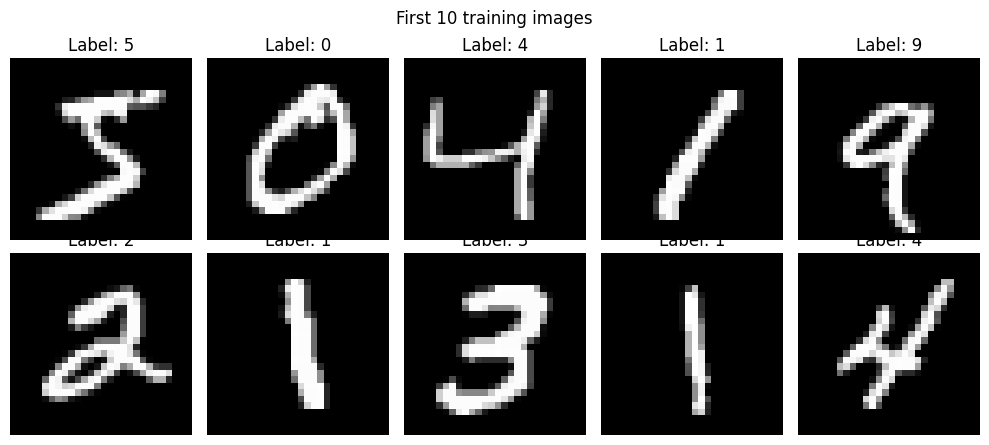

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.suptitle("First 10 training images")
plt.tight_layout()
plt.show()

### 1.3 Normalize pixel values (0-255 → 0-1) and 1.4 Flatten (28×28 → 784)

In [ ]:
# Keep a copy of the 28x28 images for displaying predictions later
x_test_img = x_test.copy()

# Normalize to 0-1
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# Flatten each 28x28 image into a 784-length vector
x_train = x_train.reshape(-1, 784)
x_test  = x_test.reshape(-1, 784)

print("x_train shape after flatten:", x_train.shape)
print("x_test shape after flatten :", x_test.shape)
print("Pixel range after normalize:", x_train.min(), "to", x_train.max())

x_train shape after flatten: (60000, 784)
x_test shape after flatten : (10000, 784)
Pixel range after normalize: 0.0 to 1.0


### 1.5 Why do we normalize pixel values?
**Answer:** Scaling pixels to 0-1 keeps the inputs small and on a similar scale, so gradient descent trains faster and more stably instead of being thrown off by large values (0-255).

## Task 2: Build and Train a Neural Network

### 2.1 Build the model
Architecture: **784 inputs → Dense(128, ReLU) → Dropout(0.2) → Dense(10, softmax)**.
The Dropout layer has no weights and is only active during training. It is the regulariser that keeps the model from overfitting.

In [ ]:
def build_model(hidden_units=128, dropout_rate=0.2, name="model"):
    model = keras.Sequential([
        keras.Input(shape=(784,)),
        layers.Dense(hidden_units, activation="relu"),
        layers.Dropout(dropout_rate),          # regularisation against overfitting
        layers.Dense(10, activation="softmax"),
    ], name=name)
    # 2.2 Compile
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model1 = build_model(hidden_units=128, name="model_1_128_neurons")
model1.summary()

Model: "model_1_128_neurons"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

### 2.2 Compile (done in `build_model`) and 2.3 Train for 10 epochs with `validation_split=0.2`

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history1 = model1.fit(
    x_train, y_train,
    epochs=10,
    validation_split=0.2,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1,
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9064 - loss: 0.3258 - val_accuracy: 0.9549 - val_loss: 0.1589
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9546 - loss: 0.1566 - val_accuracy: 0.9637 - val_loss: 0.1221
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9646 - loss: 0.1187 - val_accuracy: 0.9680 - val_loss: 0.1045
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9713 - loss: 0.0942 - val_accuracy: 0.9721 - val_loss: 0.0895
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9748 - loss: 0.0803 - val_accuracy: 0.9727 - val_loss: 0.0880
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9780 - loss: 0.0706 - val_accuracy: 0.9745 - val_loss: 0.0843
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9812 - loss: 0.0590 - val_accuracy: 0.9757 - val_loss: 0.0816
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9815 - loss: 0.0570 - 

### 2.4 Plot training vs. validation accuracy and loss

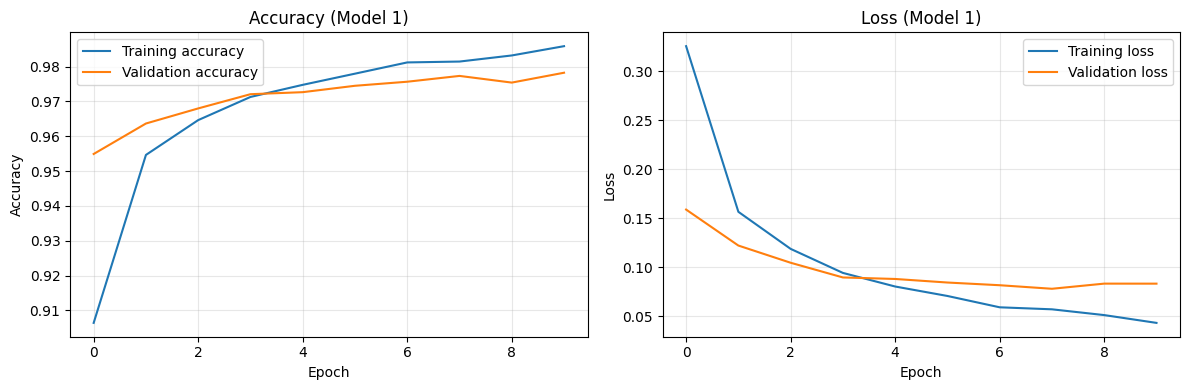

In [ ]:
def plot_history(history, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(history.history["accuracy"], label="Training accuracy")
    ax[0].plot(history.history["val_accuracy"], label="Validation accuracy")
    ax[0].set_title(f"Accuracy {title}"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy")
    ax[0].legend(); ax[0].grid(alpha=0.3)

    ax[1].plot(history.history["loss"], label="Training loss")
    ax[1].plot(history.history["val_loss"], label="Validation loss")
    ax[1].set_title(f"Loss {title}"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss")
    ax[1].legend(); ax[1].grid(alpha=0.3)
    plt.tight_layout(); plt.show()

plot_history(history1, "(Model 1)")

### 2.5 Explain briefly
**What is an epoch?** One epoch is one complete pass of the model through the entire training set. Training for 10 epochs means every training image was seen 10 times.

**What does the hidden layer do?** It learns intermediate features from the 784 raw pixels (for example strokes, curves and edges). The ReLU activation adds non-linearity, so the network can learn patterns a single linear layer cannot. The output layer then combines these features into 10 class probabilities.

## Task 3: Evaluate, Predict, and Experiment

### 3.1 Evaluate on the test set

In [ ]:
test_loss1, test_acc1 = model1.evaluate(x_test, y_test, verbose=0)
print(f"Model 1 test loss    : {test_loss1:.4f}")
print(f"Model 1 test accuracy: {test_acc1*100:.2f}%")

Model 1 test loss    : 0.0767
Model 1 test accuracy: 97.90%


#### Overfitting / generalisation check
Train accuracy is measured with dropout switched off (inference mode) on the *full* training set so it is a fair comparison against unseen data.
A gap under about 1 percentage point between train and test accuracy means the model generalises well.

In [ ]:
def generalisation_report(model, history, name):
    _, train_acc = model.evaluate(x_train, y_train, verbose=0)
    _, test_acc  = model.evaluate(x_test,  y_test,  verbose=0)
    best_val_acc = max(history.history["val_accuracy"])
    gap = (train_acc - test_acc) * 100
    print(f"--- {name} ---")
    print(f"Train accuracy     : {train_acc*100:.2f}%")
    print(f"Best validation acc: {best_val_acc*100:.2f}%")
    print(f"Test accuracy      : {test_acc*100:.2f}%")
    print(f"Train - Test gap   : {gap:.2f} percentage points")
    if gap < 1.0:
        print("Verdict: no meaningful overfitting; the model generalises to unseen data.")
    elif gap < 2.0:
        print("Verdict: slight overfitting; acceptable, but more regularisation could help.")
    else:
        print("Verdict: overfitting detected; increase dropout / reduce epochs or model size.")
    return train_acc, test_acc, gap

train_acc1, test_acc1, gap1 = generalisation_report(model1, history1, "Model 1")

--- Model 1 ---
Train accuracy     : 98.98%
Best validation acc: 97.83%
Test accuracy      : 97.90%
Train - Test gap   : 1.08 percentage points
Verdict: slight overfitting; acceptable, but more regularisation could help.


### 3.2 Predict 5 test images (predicted vs. actual)

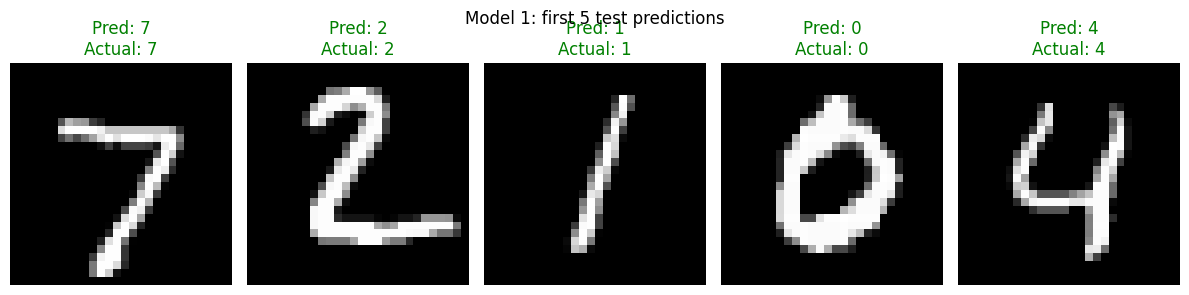

In [ ]:
probs = model1.predict(x_test, verbose=0)
y_pred = np.argmax(probs, axis=1)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(x_test_img[i], cmap="gray")
    color = "green" if y_pred[i] == y_test[i] else "red"
    ax.set_title(f"Pred: {y_pred[i]}\nActual: {y_test[i]}", color=color)
    ax.axis("off")
plt.suptitle("Model 1: first 5 test predictions")
plt.tight_layout(); plt.show()

### 3.3 Display wrongly predicted images

Total misclassified: 210 out of 10000


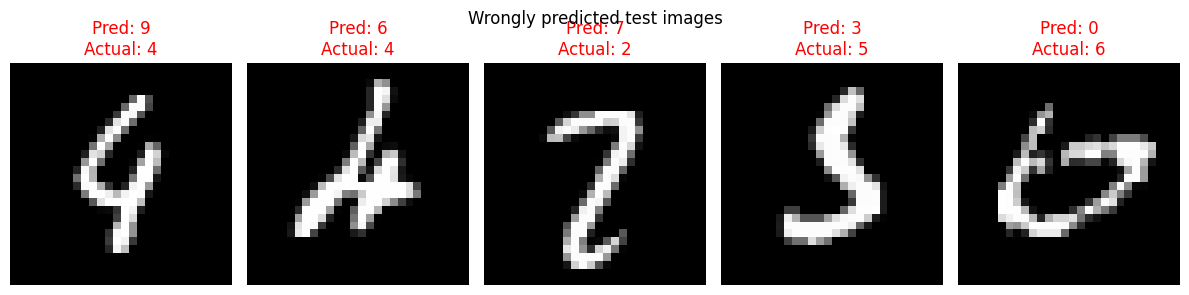

In [ ]:
wrong_idx = np.where(y_pred != y_test)[0]
print(f"Total misclassified: {len(wrong_idx)} out of {len(y_test)}")

n_show = min(5, len(wrong_idx))
fig, axes = plt.subplots(1, n_show, figsize=(12, 3))
axes = np.atleast_1d(axes)
for ax, idx in zip(axes, wrong_idx[:n_show]):
    ax.imshow(x_test_img[idx], cmap="gray")
    ax.set_title(f"Pred: {y_pred[idx]}\nActual: {y_test[idx]}", color="red")
    ax.axis("off")
plt.suptitle("Wrongly predicted test images")
plt.tight_layout(); plt.show()

### 3.4 Experiment: change ONE thing
**Change:** hidden layer neurons **128 → 256**. Everything else (epochs, dropout, optimizer, early stopping, data split) stays the same so the comparison is fair.

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9208 - loss: 0.2759 - val_accuracy: 0.9622 - val_loss: 0.1321
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9628 - loss: 0.1246 - val_accuracy: 0.9656 - val_loss: 0.1089
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9732 - loss: 0.0892 - val_accuracy: 0.9716 - val_loss: 0.0900
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9780 - loss: 0.0679 - val_accuracy: 0.9760 - val_loss: 0.0796
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9831 - loss: 0.0544 - val_accuracy: 0.9758 - val_loss: 0.0851
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9855 - loss: 0.0459 - val_accuracy: 0.9758 - val_loss: 0.0843
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9875 - loss: 0.0376 - val_accuracy: 0.9759 - val_loss: 0.0822


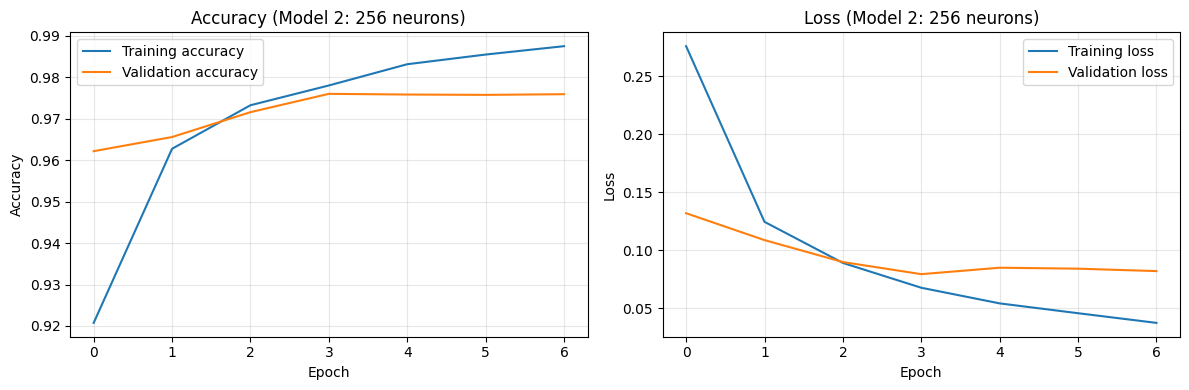

--- Model 2 ---
Train accuracy     : 98.71%
Best validation acc: 97.60%
Test accuracy      : 97.76%
Train - Test gap   : 0.95 percentage points
Verdict: no meaningful overfitting; the model generalises to unseen data.


In [ ]:
tf.keras.utils.set_random_seed(42)
model2 = build_model(hidden_units=256, name="model_2_256_neurons")

early_stop2 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

history2 = model2.fit(
    x_train, y_train,
    epochs=10,
    validation_split=0.2,
    batch_size=32,
    callbacks=[early_stop2],
    verbose=1,
)
plot_history(history2, "(Model 2: 256 neurons)")
train_acc2, test_acc2, gap2 = generalisation_report(model2, history2, "Model 2")

#### Comparison table

In [ ]:
def row(name, neurons, model, history, train_acc, test_acc, gap):
    return {
        "Model": name,
        "Hidden neurons": neurons,
        "Parameters": model.count_params(),
        "Epochs run": len(history.history["loss"]),
        "Train acc (%)": round(train_acc*100, 2),
        "Best val acc (%)": round(max(history.history["val_accuracy"])*100, 2),
        "Test acc (%)": round(test_acc*100, 2),
        "Train-Test gap (pp)": round(gap, 2),
    }

comparison = pd.DataFrame([
    row("Model 1", 128, model1, history1, train_acc1, test_acc1, gap1),
    row("Model 2", 256, model2, history2, train_acc2, test_acc2, gap2),
])
display(comparison)

diff = (test_acc2 - test_acc1) * 100
better = "Model 2 (256 neurons)" if diff > 0 else "Model 1 (128 neurons)"
print(f"Test accuracy difference (Model 2 - Model 1): {diff:+.2f} percentage points")
print(f"Higher test accuracy: {better}")
print(f"Generalisation gaps: Model 1 = {gap1:.2f} pp, Model 2 = {gap2:.2f} pp")

,Model,Hidden neurons,Parameters,Epochs run,Train acc (%),Best val acc (%),Test acc (%),Train-Test gap (pp)
0,Model 1,128,101770,10,98.98,97.83,97.90,1.08
1,Model 2,256,203530,7,98.71,97.60,97.76,0.95


Test accuracy difference (Model 2 - Model 1): -0.14 percentage points
Higher test accuracy: Model 1 (128 neurons)
Generalisation gaps: Model 1 = 1.08 pp, Model 2 = 0.95 pp


### Observations (write 2-3 lines after running)
*Fill this in using the numbers in your table above, for example:*
- Doubling the hidden neurons from 128 to 256 changed test accuracy by _-0.14__ percentage points, and increased the parameter count from _101770__ to __203530_.
- The train-to-test gap was __1.08_ pp for Model 1 and _0.95__ pp for Model 2, so (the models generalise well / one overfits more).
- Extra neurons give more capacity to learn features but with diminishing returns on a simple dataset like MNIST; dropout and early stopping kept the gap small.

## Conclusion
- Both networks were trained on normalised, flattened MNIST images using Adam and sparse categorical cross-entropy.
- **Dropout(0.2)** and **EarlyStopping (restore best weights)** were used to prevent overfitting, and the generalisation check compares train, validation and test accuracy directly.
Model 1 (128 neurons) is better here. Test acc = 97.90% vs Model 2 = 97.76%. Doubling neurons almost doubled parameters but test accuracy _decreased* by 0.14 pp. Train-test gap is small for both (1.08 pp and 0.95 pp) = no major overfitting.
- A basic model like this is expected to reach roughly **97-98% test accuracy**, with train and test accuracy within about 1 percentage point.